# SH Bridge Analysis
## Analysis 1: Bridge Moment Restriction Residual (Proposition 1)
## Analysis 2: Credit Contrast (Theorem 1 / Eq. 12-13)

Checkpoint-based analysis of the trained outcome bridge $h_\varphi$ on Stag-Hunt environments.

In [7]:
import sys, os
from pathlib import Path

NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent
sys.path.insert(0, str(PROJECT_ROOT))
sys.path.insert(0, str(NOTEBOOK_DIR))

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import TwoSlopeNorm
import torch
from scipy import stats
from tqdm.notebook import tqdm

from sh_analysis_utils import (
    get_checkpoint_paths, load_bridge_and_agents,
    make_random_bridge, make_env, collect_rollout_data,
    bridge_residuals, bridge_outputs_all_actions,
    NUM_AGENTS, OBS_DIM, ACTION_DIM,
    SCENARIO_ORDER, ACTION_NAMES,
)

print(f"Project root : {PROJECT_ROOT}")
print(f"Notebook dir : {NOTEBOOK_DIR}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"Dims  OBS={OBS_DIM}  ACT={ACTION_DIM}  N_AGENTS={NUM_AGENTS}")

Project root : /home/chamjin/research/pci_marl
Notebook dir : /home/chamjin/research/pci_marl/SH_analysis
CUDA available: True
Dims  OBS=175  ACT=5  N_AGENTS=3


In [8]:
# ── Style — matching figures/ notebooks ───────────────────────────────────────
FS      = 22       # up from 18; SH_FONT_SIZE = 20 in existing notebooks
LW      = 3.0      # up from 2.5
FILL_A  = 0.18
GRID_A  = 0.45

MODEL_COLORS = {"ipci": "#0050a4", "mpci": "#b00020"}
MODEL_LABELS = {"ipci": "PCI-IPPO",  "mpci": "PCI-MAPPO"}

SCENARIO_COLORS     = {"Stag": "#0050a4", "Hare": "#b00020", "Null": "#888888"}
SCENARIO_LINESTYLES = {"Stag": "-",       "Hare": "--",      "Null": ":"}
SCENARIO_MARKERS    = {"Stag": "o",       "Hare": "s",       "Null": "^"}

plt.rcParams.update({
    "font.size":          FS,
    "axes.labelsize":     FS,
    "axes.titlesize":     FS,
    "legend.fontsize":    FS - 2,
    "xtick.labelsize":    FS - 2,
    "ytick.labelsize":    FS - 2,
    "axes.linewidth":     1.6,
    "xtick.major.width":  1.4,
    "ytick.major.width":  1.4,
    "xtick.major.size":   5,
    "ytick.major.size":   5,
    "axes.grid":          True,
    "grid.linestyle":     "--",
    "grid.alpha":         GRID_A,
    "axes.spines.top":    False,
    "axes.spines.right":  False,
    "figure.dpi":         120,
})

VARIANTS = [
    ("PCI-IPPO\nNo Noise",   "sh3",       "ipci", 0.0),
    ("PCI-MAPPO\nNo Noise",  "sh3",       "mpci", 0.0),
    ("PCI-IPPO\nNoisy Obs",  "sh3_noise", "ipci", 0.1),
    ("PCI-MAPPO\nNoisy Obs", "sh3_noise", "mpci", 0.1),
]

N_EPISODES_PER_SEED = 200
MAX_SEEDS            = 5
DEVICE               = "cpu"
SAVE_DIR             = NOTEBOOK_DIR
print("Style configured.")

Style configured.


## Quick Smoke Test (1 seed, 10 episodes)

In [9]:
# Quick sanity check before full data collection
_path = get_checkpoint_paths("sh3", "ipci")[0]
_bridge, _agents = load_bridge_and_agents(_path, DEVICE)
_env   = make_env(obs_noise_std=0.0)
_recs  = collect_rollout_data(_agents, _env, n_episodes=10)

assert "policy_probs" in _recs[0], "policy_probs not found in records"
assert _recs[0]["policy_probs"].shape == (ACTION_DIM,)
assert "w" in _recs[0] and _recs[0]["w"].shape == (350,)
assert "x" in _recs[0] and _recs[0]["x"].shape == (313,)

_h_all = bridge_outputs_all_actions(_bridge, _recs, DEVICE)
_res   = bridge_residuals(_bridge, _recs, DEVICE)

print(f"Records: {len(_recs)}")
print(f"Scenarios: { {sc: sum(r['scenario']==sc for r in _recs) for sc in SCENARIO_ORDER} }")
print(f"h_all shape: {_h_all.shape}")
print(f"Residual:  mean={_res.mean():.4f}  std={_res.std():.4f}")
print(f"policy_probs[0]: {_recs[0]['policy_probs'].round(3)}  sum={_recs[0]['policy_probs'].sum():.4f}")
print("\n✓ Smoke test PASSED")

Records: 1128
Scenarios: {'Stag': 26, 'Hare': 59, 'Null': 1043}
h_all shape: (1128, 5)
Residual:  mean=0.0691  std=0.3465
policy_probs[0]: [0.712 0.267 0.    0.002 0.019]  sum=1.0000

✓ Smoke test PASSED


## Full Data Collection

In [10]:
all_variant_data = {}  # key -> dict with records, bridges, etc.

for display, variant, model_type, noise in VARIANTS:
    key  = display.replace("\n", " ")
    mkey = model_type
    print(f"\n[{key}]")

    env   = make_env(obs_noise_std=noise)
    paths = get_checkpoint_paths(variant, model_type)[:MAX_SEEDS]

    if not paths:
        print("  No checkpoints found — skipping"); continue

    all_records    = []
    trained_bridge = None

    for path in paths:
        seed_tag = Path(path).parts[-4]
        print(f"  loading {seed_tag} ...", end=" ", flush=True)
        bridge, agents = load_bridge_and_agents(path, DEVICE)
        if trained_bridge is None:
            trained_bridge = bridge
        recs = collect_rollout_data(agents, env, n_episodes=N_EPISODES_PER_SEED)
        all_records.extend(recs)
        print(f"{len(recs)} transitions")

    sc_counts = {sc: sum(r["scenario"]==sc for r in all_records) for sc in SCENARIO_ORDER}
    print(f"  Total: {len(all_records)} transitions | {sc_counts}")

    all_variant_data[key] = {
        "records":        all_records,
        "trained_bridge": trained_bridge,
        "random_bridge":  make_random_bridge(),
        "model_type":     mkey,
        "noise":          noise,
        "display":        display,
    }

print("\n✓ Data collection complete.")


[PCI-IPPO No Noise]
  loading 20260430_005950_seed42 ... 19584 transitions
  loading 20260430_083833_seed2 ... 19293 transitions
  loading 20260430_110536_seed1 ... 21498 transitions
  loading 20260430_122334_seed31 ... 20019 transitions
  loading 20260430_160243_seed32 ... 23172 transitions
  Total: 103566 transitions | {'Stag': 2690, 'Hare': 5713, 'Null': 95163}

[PCI-MAPPO No Noise]
  loading 20260430_010011_seed42 ... 20490 transitions
  loading 20260430_040838_seed1 ... 19260 transitions
  loading 20260430_071733_seed2 ... 20247 transitions
  loading 20260430_102727_seed31 ... 19713 transitions
  loading 20260430_133326_seed32 ... 20328 transitions
  Total: 100038 transitions | {'Stag': 2760, 'Hare': 5707, 'Null': 91571}

[PCI-IPPO Noisy Obs]
[WARN] Skipping empty checkpoint: /home/chamjin/research/pci_marl/checkpoints_for_eval/sh3_noise/ipci/20260501_124621_seed32/staghuntenv/checkpoints/final_checkpoint.pt
  loading 20260430_200604_seed42 ... 24525 transitions
  loading 2026043

In [11]:
def compute_credit_quantities(records, bridge_net, device=DEVICE):
    """
    Returns per-record arrays.
    h_all        : (N, A)  bridge output for every action
    h_fact       : (N,)    bridge output at factual action
    baseline_uni : (N,)    uniform baseline (mean over a' != a)
    baseline_pol : (N,)    policy-weighted baseline  Eq.(13)
    credit_pol   : (N,)    r_tilde = R - baseline_pol
    reward       : (N,)    global reward R
    scenario     : (N,)    str array
    action       : (N,)    int array
    res_trained  : (N,)    R - h_phi(W, A_factual, X)
    """
    h_all    = bridge_outputs_all_actions(bridge_net, records, device)
    actions  = np.array([r["action"]        for r in records])
    rewards  = np.array([r["global_reward"] for r in records])
    scenarios = np.array([r["scenario"]     for r in records])

    N      = len(records)
    h_fact = h_all[np.arange(N), actions]

    baseline_uni = (h_all.sum(axis=1) - h_fact) / (ACTION_DIM - 1)

    # Policy-weighted baseline — Eq.(13)
    probs    = np.stack([r["policy_probs"] for r in records])
    p_fact   = probs[np.arange(N), actions]
    denom    = np.clip(1.0 - p_fact, 1e-8, None)
    probs_cf = probs.copy()
    probs_cf[np.arange(N), actions] = 0.0
    probs_cf /= denom[:, None]
    baseline_pol = (probs_cf * h_all).sum(axis=1)

    return {
        "h_all":        h_all,
        "h_fact":       h_fact,
        "baseline_uni": baseline_uni,
        "baseline_pol": baseline_pol,
        "credit_pol":   rewards - baseline_pol,
        "reward":       rewards,
        "scenario":     scenarios,
        "action":       actions,
    }

variant_q = {}
for key, vd in all_variant_data.items():
    q = compute_credit_quantities(vd["records"], vd["trained_bridge"])
    q["res_trained"] = bridge_residuals(vd["trained_bridge"], vd["records"], DEVICE)
    q["res_random"]  = bridge_residuals(vd["random_bridge"],  vd["records"], DEVICE)
    variant_q[key] = q
    print(f"[{key}]  N={len(vd['records'])}")

print("\n✓ All quantities ready.")

[PCI-IPPO No Noise]  N=103566
[PCI-MAPPO No Noise]  N=100038
[PCI-IPPO Noisy Obs]  N=99693
[PCI-MAPPO Noisy Obs]  N=127014

✓ All quantities ready.


---
## Analysis 1 — Bridge Moment Restriction Residual

**Claim** (Proposition 1 / Theorem 1):  The trained bridge $h_\varphi$ satisfies the observed moment restriction:

$$\mathbb{E}\left[ R_t - h_\varphi(O^{-i}_t, A^i_t, X^i_t) \mid T^i_{t-1}, A^i_t, X^i_t \right] \approx 0$$

**Empirical check**: We plot the residual distribution $R - \hat{h}_\varphi(W, A, X)$ per scenario type,
comparing the **trained bridge** against a **randomly-initialised bridge** of identical architecture.

- Near-zero residuals → moment condition is well satisfied by the trained bridge.
- Large residuals for the random bridge → the training is non-trivial (not trivially satisfied by construction).

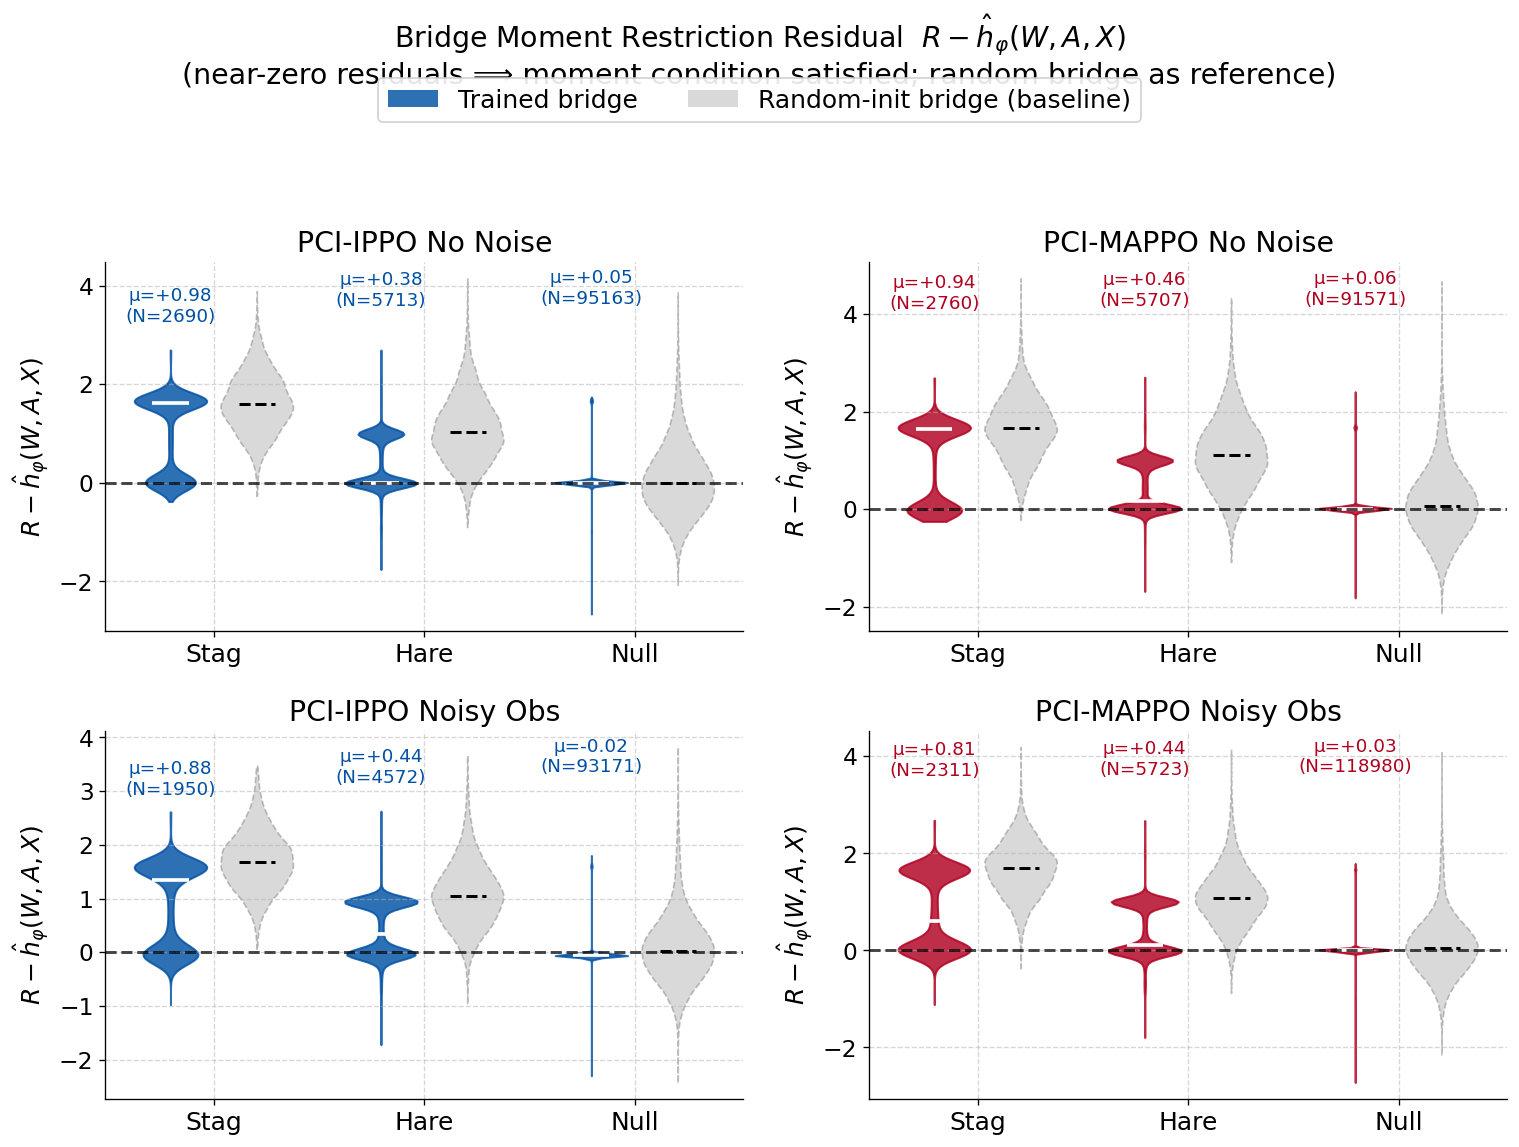

Saved: bridge_residual_violin.pdf


In [12]:
# ── Figure 1: Bridge residual violin (2 × 2) ─────────────────────────────────
# Data flow:
#   records[i] → (action, global_reward, W, X)
#   residual   = R  −  h_φ(W, A_factual, X)       ← bridge evaluated at observed action
#   Grouped by scenario (Stag / Hare / Null)
#   Comparison: trained bridge  vs  random-init bridge (same architecture, untrained)

fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharey=False)
axes_flat = axes.flatten()
keys = list(all_variant_data.keys())

for ax, key in zip(axes_flat, keys):
    vd    = all_variant_data[key]
    q     = variant_q[key]
    color = MODEL_COLORS[vd["model_type"]]
    res_tr = q["res_trained"]
    res_ra = q["res_random"]
    scens  = q["scenario"]

    pos    = np.array([0.0, 1.8, 3.6])
    offset = 0.38
    _annot = []  # (x, mu, sd, color) — placed after ylim is finalized

    for idx, sc in enumerate(SCENARIO_ORDER):
        mask = scens == sc
        n    = mask.sum()
        if n == 0:
            continue
        x_tr = pos[idx] - offset
        x_ra = pos[idx] + offset

        # trained bridge
        vp_tr = ax.violinplot([res_tr[mask]], positions=[x_tr], widths=0.65,
                               showmedians=True, showextrema=False)
        for body in vp_tr["bodies"]:
            body.set_facecolor(color); body.set_alpha(0.82)
            body.set_edgecolor(color); body.set_linewidth(1.8)
        vp_tr["cmedians"].set_color("white"); vp_tr["cmedians"].set_linewidth(2.8)

        # random bridge
        vp_ra = ax.violinplot([res_ra[mask]], positions=[x_ra], widths=0.65,
                               showmedians=True, showextrema=False)
        for body in vp_ra["bodies"]:
            body.set_facecolor("#bbbbbb"); body.set_alpha(0.55)
            body.set_edgecolor("#888888"); body.set_linewidth(1.4)
        vp_ra["cmedians"].set_color("black"); vp_ra["cmedians"].set_linewidth(2.2)
        vp_ra["cmedians"].set_linestyle("--")

        _annot.append((x_tr, res_tr[mask].mean(), res_tr[mask].std(), n, color))

    ax.axhline(0, color="black", lw=2.0, ls="--", alpha=0.75, zorder=3)
    ax.set_xticks(pos)
    ax.set_xticklabels(SCENARIO_ORDER, fontsize=FS - 2)
    ax.set_ylabel(r"$R - \hat{h}_\varphi(W, A, X)$", fontsize=FS - 1)
    ax.set_title(vd["display"].replace("\n", " "), fontsize=FS)

    # annotations placed after ylim is set
    y_top = ax.get_ylim()[1]
    for x_tr, mu, sd, n, c in _annot:
        ax.text(x_tr, y_top * 0.96, f"μ={mu:+.2f}\nN={n}",
                ha="center", va="top", fontsize=FS - 6, color=c, fontweight="bold")

leg_handles = [
    mpatches.Patch(facecolor=MODEL_COLORS["ipci"], alpha=0.82, label="Trained bridge"),
    mpatches.Patch(facecolor="#bbbbbb", alpha=0.55, label="Random-init bridge (baseline)"),
]
fig.legend(handles=leg_handles, loc="upper center", ncol=2,
           bbox_to_anchor=(0.5, 1.02), fontsize=FS - 1, framealpha=0.9)
fig.suptitle(
    r"Bridge Moment Restriction Residual  $R - \hat{h}_\varphi(W, A, X)$"
    "\n(near-zero  →  moment condition satisfied;  random bridge as reference)",
    fontsize=FS, y=1.08,
)
plt.tight_layout()
plt.savefig(SAVE_DIR / "bridge_residual_violin.pdf", dpi=200, bbox_inches="tight")
plt.show()
print("Saved: bridge_residual_violin.pdf")

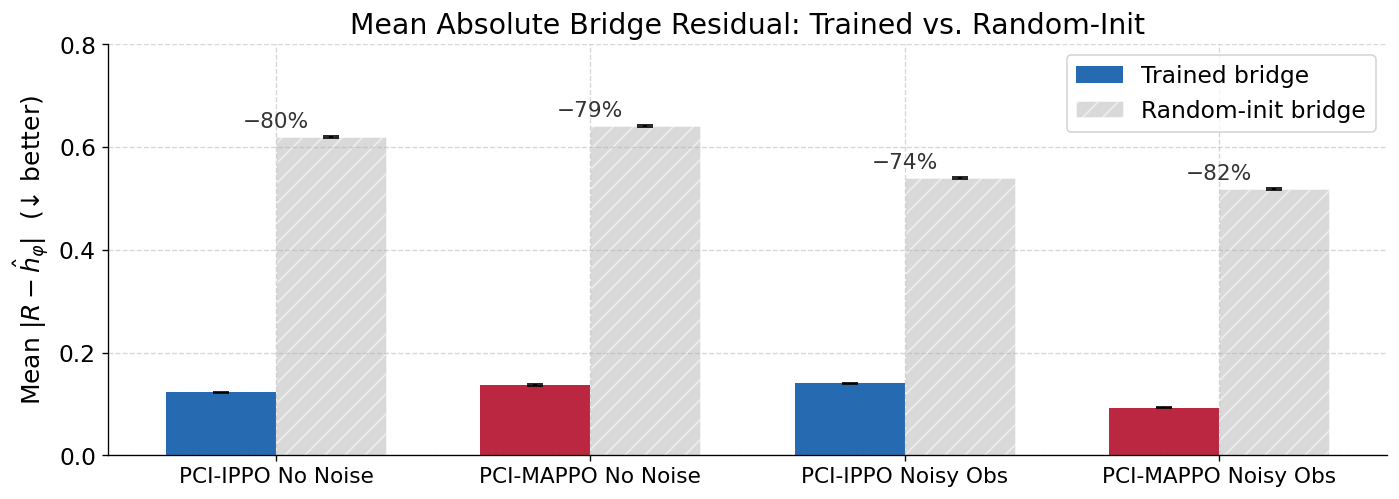

Saved: bridge_residual_mae.pdf


In [13]:
# ── Figure 1b: MAE bar chart ─────────────────────────────────────────────────
# Data flow:
#   MAE = mean( |R − h_φ(W, A, X)| )  computed over ALL transitions
#   Side-by-side: trained vs random-init bridge for each of the 4 variants

fig, ax = plt.subplots(figsize=(13, 5.5))
n_var  = len(variant_q)
x      = np.arange(n_var)
width  = 0.35
keys   = list(variant_q.keys())

mae_tr, sem_tr, mae_ra, sem_ra = [], [], [], []
for key in keys:
    q    = variant_q[key]
    r_tr = np.abs(q["res_trained"])
    r_ra = np.abs(q["res_random"])
    mae_tr.append(r_tr.mean());  sem_tr.append(r_tr.std() / np.sqrt(len(r_tr)))
    mae_ra.append(r_ra.mean());  sem_ra.append(r_ra.std() / np.sqrt(len(r_ra)))

colors_tr = [MODEL_COLORS[all_variant_data[k]["model_type"]] for k in keys]

ax.bar(x - width / 2, mae_tr, width, yerr=sem_tr, color=colors_tr, alpha=0.85,
       label="Trained bridge",
       error_kw=dict(elinewidth=2.0, capsize=6))
ax.bar(x + width / 2, mae_ra, width, yerr=sem_ra, color="#bbbbbb", alpha=0.55,
       label="Random-init bridge", hatch="//", edgecolor="white", linewidth=0,
       error_kw=dict(elinewidth=2.0, capsize=6))

for i, (m_tr, m_ra) in enumerate(zip(mae_tr, mae_ra)):
    pct = (1 - m_tr / m_ra) * 100
    ax.text(i, max(m_tr, m_ra) + 0.012, f"−{pct:.0f}%",
            ha="center", va="bottom", fontsize=FS - 3, color="#333333", fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels([k.replace(" (", "\n(") for k in keys], fontsize=FS - 3)
ax.set_ylabel(r"Mean $|R - \hat{h}_\varphi|$  (↓ better)", fontsize=FS - 1)
ax.set_title("Mean Absolute Bridge Residual: Trained vs. Random-Init", fontsize=FS)
ax.legend(fontsize=FS - 2, loc="upper right")
ax.set_ylim(0, max(mae_ra) * 1.3)

plt.tight_layout()
plt.savefig(SAVE_DIR / "bridge_residual_mae.pdf", dpi=200, bbox_inches="tight")
plt.show()
print("Saved: bridge_residual_mae.pdf")

In [14]:
# ── Console summary: residual statistics ─────────────────────────────────────
from scipy.stats import ttest_1samp, mannwhitneyu

print(f"{'Variant':<28}  {'Scenario':>8}  {'N':>6}  {'μ_trained':>10}  "
      f"{'σ_trained':>10}  {'μ_random':>9}  {'|Δ|/σ_r':>8}  {'p(μ=0)':>8}")
print("-" * 100)
for key, q in variant_q.items():
    for sc in SCENARIO_ORDER:
        mask = q["scenario"] == sc
        n    = mask.sum()
        if n == 0: continue
        mu_tr = q["res_trained"][mask].mean()
        sd_tr = q["res_trained"][mask].std()
        mu_ra = q["res_random"][mask].mean()
        sd_ra = q["res_random"][mask].std()
        ratio = abs(mu_tr) / (sd_ra + 1e-8)
        t, p  = ttest_1samp(q["res_trained"][mask], 0.0)
        print(f"  {key:<26}  {sc:>8}  {n:>6}  {mu_tr:>+10.4f}  "
              f"{sd_tr:>10.4f}  {mu_ra:>+9.4f}  {ratio:>8.4f}  {p:>8.4f}")
    print()

Variant                       Scenario       N   μ_trained   σ_trained   μ_random   |Δ|/σ_r    p(μ=0)
----------------------------------------------------------------------------------------------------
  PCI-IPPO No Noise               Stag    2690     +0.9775      0.7943    +1.6242    1.6245    0.0000
  PCI-IPPO No Noise               Hare    5713     +0.3759      0.5426    +1.0827    0.5458    0.0000
  PCI-IPPO No Noise               Null   95163     +0.0480      0.3370    +0.0689    0.0660    0.0000

  PCI-MAPPO No Noise              Stag    2760     +0.9373      0.8299    +1.6683    1.4830    0.0000
  PCI-MAPPO No Noise              Hare    5707     +0.4629      0.5145    +1.1440    0.6317    0.0000
  PCI-MAPPO No Noise              Null   91571     +0.0641      0.3479    +0.1287    0.0863    0.0000

  PCI-IPPO Noisy Obs              Stag    1950     +0.8782      0.7758    +1.7014    1.6134    0.0000
  PCI-IPPO Noisy Obs              Hare    4572     +0.4360      0.5169    +1.0757

---
## Analysis 2 — Credit Contrast Heatmap

**Claim** (Theorem 1 / Eq. 12–13):  The trained bridge $h_\varphi$ correctly differentiates the causal
contribution of each action across scenario types:

- **Stag**: Factual action (coordination move) ≫ counterfactual actions → high credit $\tilde{r}^i_t \approx R$
- **Hare**: Roughly uniform over actions → moderate credit
- **Null**: Near-zero for all actions → credit $\approx 0$

We evaluate $\hat{h}_\varphi(W^i_t, a', X^i_t)$ for **all** $a' \in \mathcal{A}^i$ at each observed context,
then aggregate per scenario type.

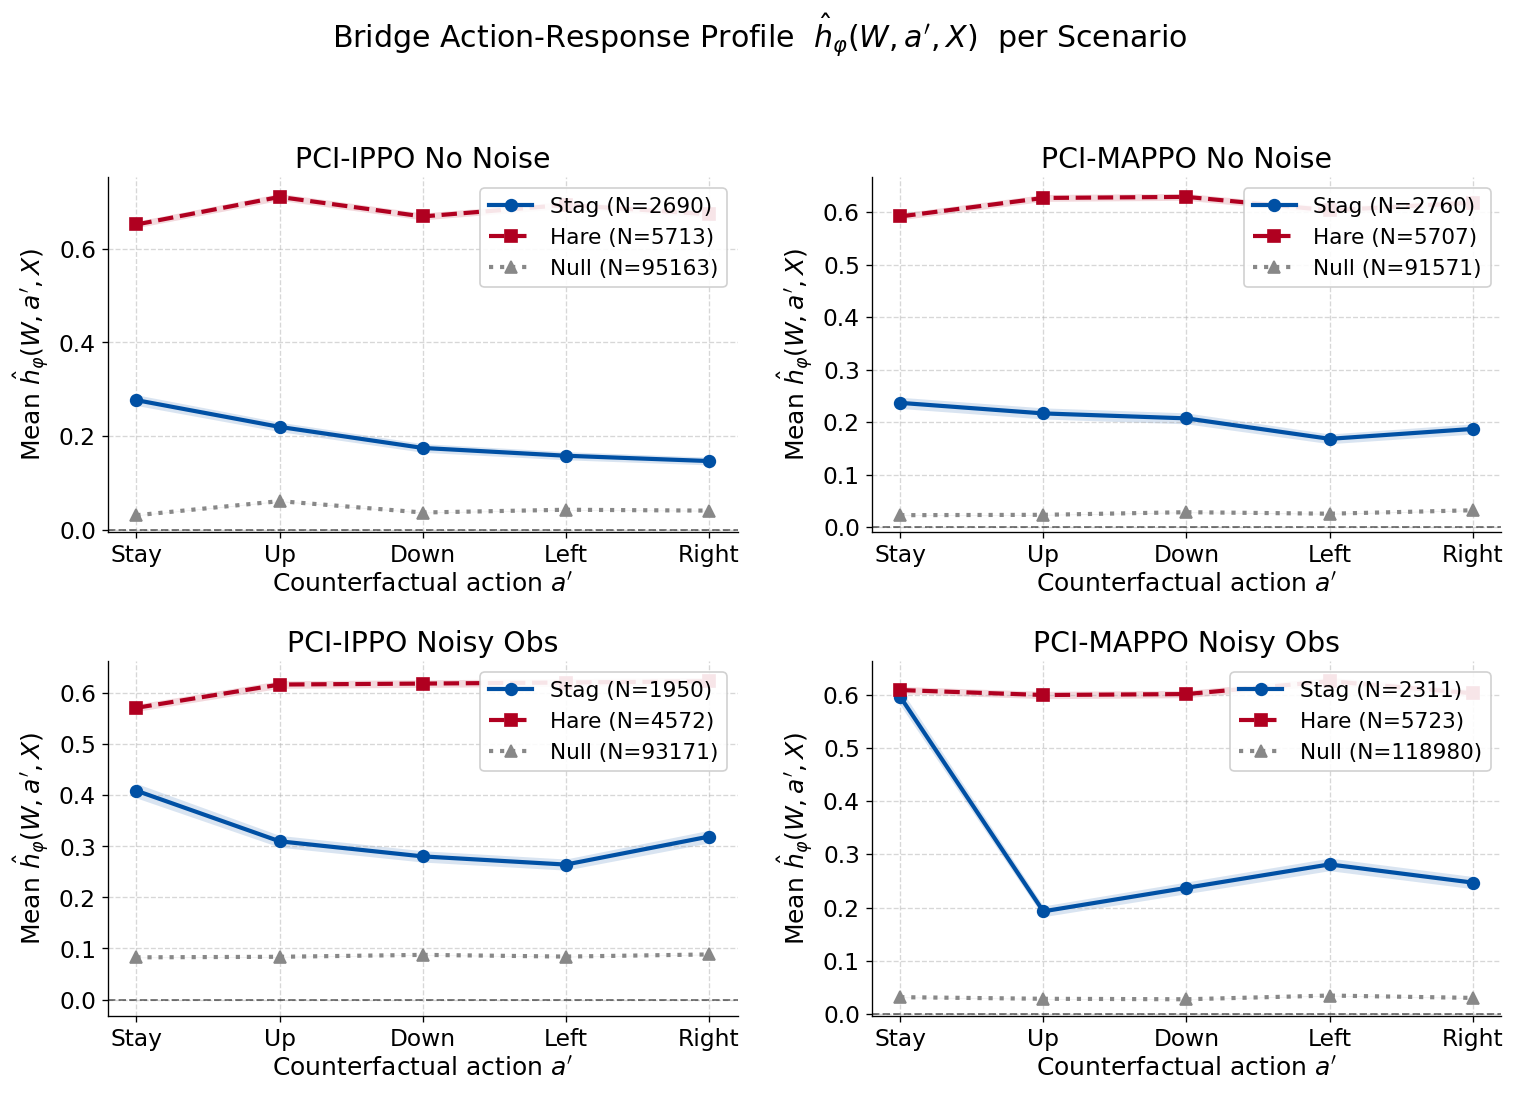

Saved: credit_action_profile.pdf


In [15]:
# ── Figure 2a: Action response profile ───────────────────────────────────────
# Data flow:
#   For each transition: evaluate h_φ(W, a', X) for ALL 5 actions a'  →  h_all (N, 5)
#   Grouped by scenario; compute mean ± SEM over transitions
#   Line plot: x = action, y = mean bridge output
#   Key insight: in Stag contexts the factual (coordination) action has highest output;
#                in Null contexts all actions produce near-zero output.

fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharey=False)
action_labels = [ACTION_NAMES[a] for a in range(ACTION_DIM)]
x_act = np.arange(ACTION_DIM)

row_map = {"ipci_0.0": (0, 0), "mpci_0.0": (0, 1),
           "ipci_0.1": (1, 0), "mpci_0.1": (1, 1)}

for key, vd in all_variant_data.items():
    ax    = axes[row_map[f"{vd['model_type']}_{vd['noise']}"]]
    q     = variant_q[key]
    h_all = q["h_all"]
    scens = q["scenario"]

    for sc in SCENARIO_ORDER:
        mask = scens == sc
        n    = mask.sum()
        if n == 0:
            continue
        mean_h = h_all[mask].mean(axis=0)
        sem_h  = h_all[mask].std(axis=0) / np.sqrt(n)

        ax.plot(x_act, mean_h,
                color=SCENARIO_COLORS[sc], linestyle=SCENARIO_LINESTYLES[sc],
                marker=SCENARIO_MARKERS[sc], markersize=10, linewidth=LW,
                label=f"{sc} (N={n})")
        ax.fill_between(x_act, mean_h - sem_h, mean_h + sem_h,
                        color=SCENARIO_COLORS[sc], alpha=FILL_A, linewidth=0)

    ax.axhline(0, color="black", lw=1.5, ls="--", alpha=0.5)
    ax.set_xticks(x_act)
    ax.set_xticklabels(action_labels, fontsize=FS - 2)
    ax.set_xlabel("Counterfactual action $a'$", fontsize=FS - 1)
    ax.set_ylabel(r"Mean $\hat{h}_\varphi(W, a', X)$", fontsize=FS - 1)
    ax.set_title(vd["display"].replace("\n", " "), fontsize=FS)
    ax.legend(loc="upper right", fontsize=FS - 3, framealpha=0.9)

fig.suptitle(
    r"Bridge Action-Response Profile  $\hat{h}_\varphi(W, a', X)$  per Scenario",
    fontsize=FS + 1, y=1.02,
)
plt.tight_layout()
plt.savefig(SAVE_DIR / "credit_action_profile.pdf", dpi=200, bbox_inches="tight")
plt.show()
print("Saved: credit_action_profile.pdf")

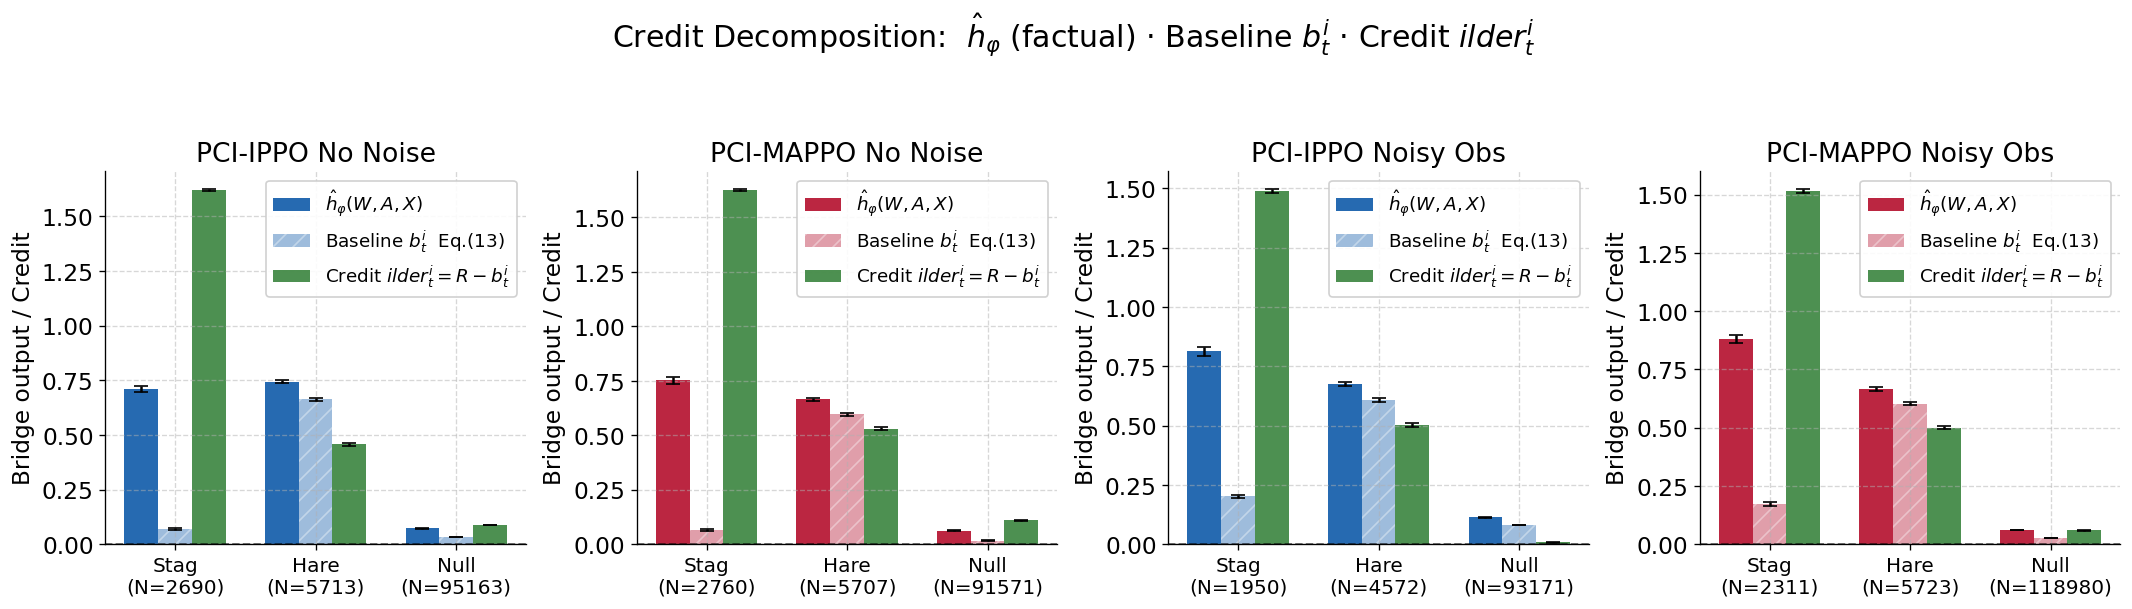

Saved: credit_decomposition.pdf


In [16]:
# ── Figure 2b: Credit decomposition ──────────────────────────────────────────
# Data flow per transition:
#   h_fact       = h_φ(W, A_factual, X)
#   baseline_pol = Σ_{a'≠a} π̄^i(a') · h_φ(W, a', X)   (policy-weighted, Eq.13)
#                  π̄^i(a') = π(a'|τ) / (1 − π(a|τ))  for a' ≠ a
#   credit       = R − baseline_pol
# Grouped by scenario; plot mean ± SEM for each of the 3 quantities

fig, axes = plt.subplots(1, 4, figsize=(20, 6), sharey=False)
sc_x  = np.arange(len(SCENARIO_ORDER))
bar_w = 0.24

for ax, key in zip(axes, list(all_variant_data.keys())):
    vd    = all_variant_data[key]
    q     = variant_q[key]
    color = MODEL_COLORS[vd["model_type"]]
    scens = q["scenario"]

    hf_m, hf_e, bp_m, bp_e, cr_m, cr_e, ns = [], [], [], [], [], [], []
    for sc in SCENARIO_ORDER:
        mask = scens == sc
        n    = mask.sum(); ns.append(n)
        se   = lambda arr: arr[mask].std() / np.sqrt(max(n, 1))
        hf_m.append(q["h_fact"][mask].mean()       if n > 0 else 0.0); hf_e.append(se(q["h_fact"]))
        bp_m.append(q["baseline_pol"][mask].mean() if n > 0 else 0.0); bp_e.append(se(q["baseline_pol"]))
        cr_m.append(q["credit_pol"][mask].mean()   if n > 0 else 0.0); cr_e.append(se(q["credit_pol"]))

    ew = dict(error_kw=dict(elinewidth=2.0, capsize=5))
    ax.bar(sc_x - bar_w, hf_m, bar_w, yerr=hf_e, color=color, alpha=0.85,
           label=r"$\hat{h}_\varphi(W,A,X)$", **ew)
    ax.bar(sc_x,          bp_m, bar_w, yerr=bp_e, color=color, alpha=0.38,
           hatch="//", edgecolor="white", linewidth=0,
           label=r"Baseline $b^i_t$  Eq.(13)", **ew)
    ax.bar(sc_x + bar_w,  cr_m, bar_w, yerr=cr_e, color="#2e7d32", alpha=0.85,
           label=r"Credit $\tilde{r}^i_t = R - b^i_t$", **ew)

    ax.axhline(0, color="black", lw=1.5, ls="--", alpha=0.5)
    ax.set_xticks(sc_x)
    ax.set_xticklabels([f"{sc}\n(N={n})" for sc, n in zip(SCENARIO_ORDER, ns)], fontsize=FS - 4)
    ax.set_title(vd["display"].replace("\n", " "), fontsize=FS)
    ax.set_ylabel("Bridge output / Credit", fontsize=FS - 1)
    ax.legend(fontsize=FS - 5, loc="upper right", framealpha=0.9)

fig.suptitle(
    r"Credit Decomposition:  $\hat{h}_\varphi$ (factual) · Baseline $b^i_t$ · Credit $\tilde{r}^i_t$",
    fontsize=FS + 1, y=1.04,
)
plt.tight_layout()
plt.savefig(SAVE_DIR / "credit_decomposition.pdf", dpi=200, bbox_inches="tight")
plt.show()
print("Saved: credit_decomposition.pdf")

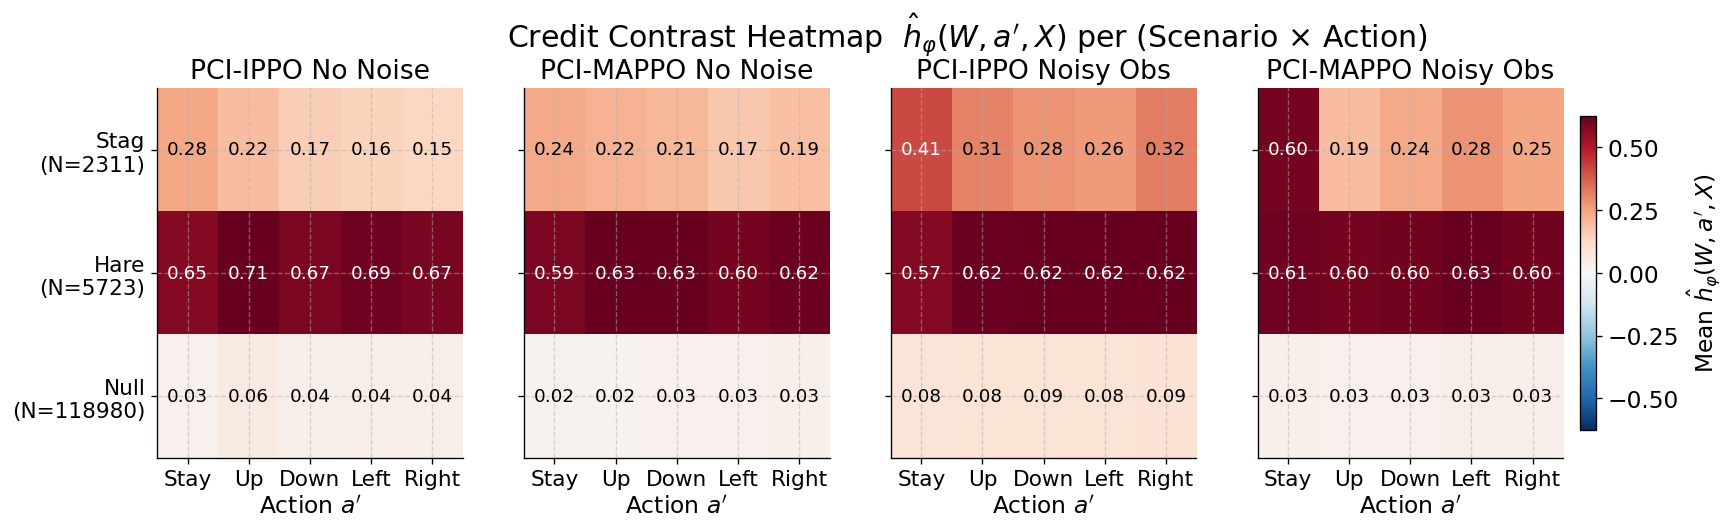

Saved: credit_heatmap.pdf


In [17]:
# ── Figure 2c: Credit contrast heatmap ───────────────────────────────────────
# Data flow:
#   h_all[i, a'] = h_φ(W^i_t, a', X^i_t)  for all actions a' ∈ {0..4}
#   Grid cell (scenario, action) = mean h_all over all transitions in that scenario
#   Colour scale: RdBu_r centred at 0
#   Pattern: Stag row should be brightest at the factual (coordination) action;
#            Null row should be near-zero across all actions.

fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharey=True)
action_labels = [ACTION_NAMES[a] for a in range(ACTION_DIM)]

ims = []
for ax, key in zip(axes, list(all_variant_data.keys())):
    vd    = all_variant_data[key]
    q     = variant_q[key]
    h_all = q["h_all"]
    scens = q["scenario"]

    grid   = np.full((len(SCENARIO_ORDER), ACTION_DIM), np.nan)
    counts = []
    for r, sc in enumerate(SCENARIO_ORDER):
        mask = scens == sc
        n    = mask.sum(); counts.append(n)
        if n > 0:
            grid[r] = h_all[mask].mean(axis=0)

    vmax = max(np.nanmax(np.abs(grid)), 1e-3)
    norm = TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)
    im   = ax.imshow(grid, cmap="RdBu_r", norm=norm, aspect="auto")
    ims.append(im)

    ax.set_xticks(range(ACTION_DIM))
    ax.set_xticklabels(action_labels, fontsize=FS - 2)
    ax.set_yticks(range(len(SCENARIO_ORDER)))
    ax.set_yticklabels([f"{sc}\n(N={n})" for sc, n in zip(SCENARIO_ORDER, counts)], fontsize=FS - 2)
    ax.set_title(vd["display"].replace("\n", " "), fontsize=FS)
    ax.set_xlabel("Action $a'$", fontsize=FS - 1)

    for r in range(len(SCENARIO_ORDER)):
        for c in range(ACTION_DIM):
            v = grid[r, c]
            if not np.isnan(v):
                ax.text(c, r, f"{v:.2f}", ha="center", va="center",
                        fontsize=FS - 5,
                        color="white" if abs(v) > vmax * 0.55 else "black")

cbar = fig.colorbar(ims[-1], ax=axes.tolist(), shrink=0.82, pad=0.01)
cbar.set_label(r"Mean $\hat{h}_\varphi(W, a', X)$", fontsize=FS - 1)
cbar.ax.tick_params(labelsize=FS - 3)

fig.suptitle(
    r"Credit Contrast Heatmap  $\hat{h}_\varphi(W, a', X)$  per (Scenario $\times$ Action)",
    fontsize=FS + 1, y=1.04,
)
plt.savefig(SAVE_DIR / "credit_heatmap.pdf", dpi=200, bbox_inches="tight")
plt.show()
print("Saved: credit_heatmap.pdf")

### Normalised credit $\tilde{r}^i_t / R_t$  (cf. Figure 2b in paper)

The paper reports $\tilde{r}^i_t / r_t$ during training.
Here we show the **static distribution at convergence** (using the final checkpoint).

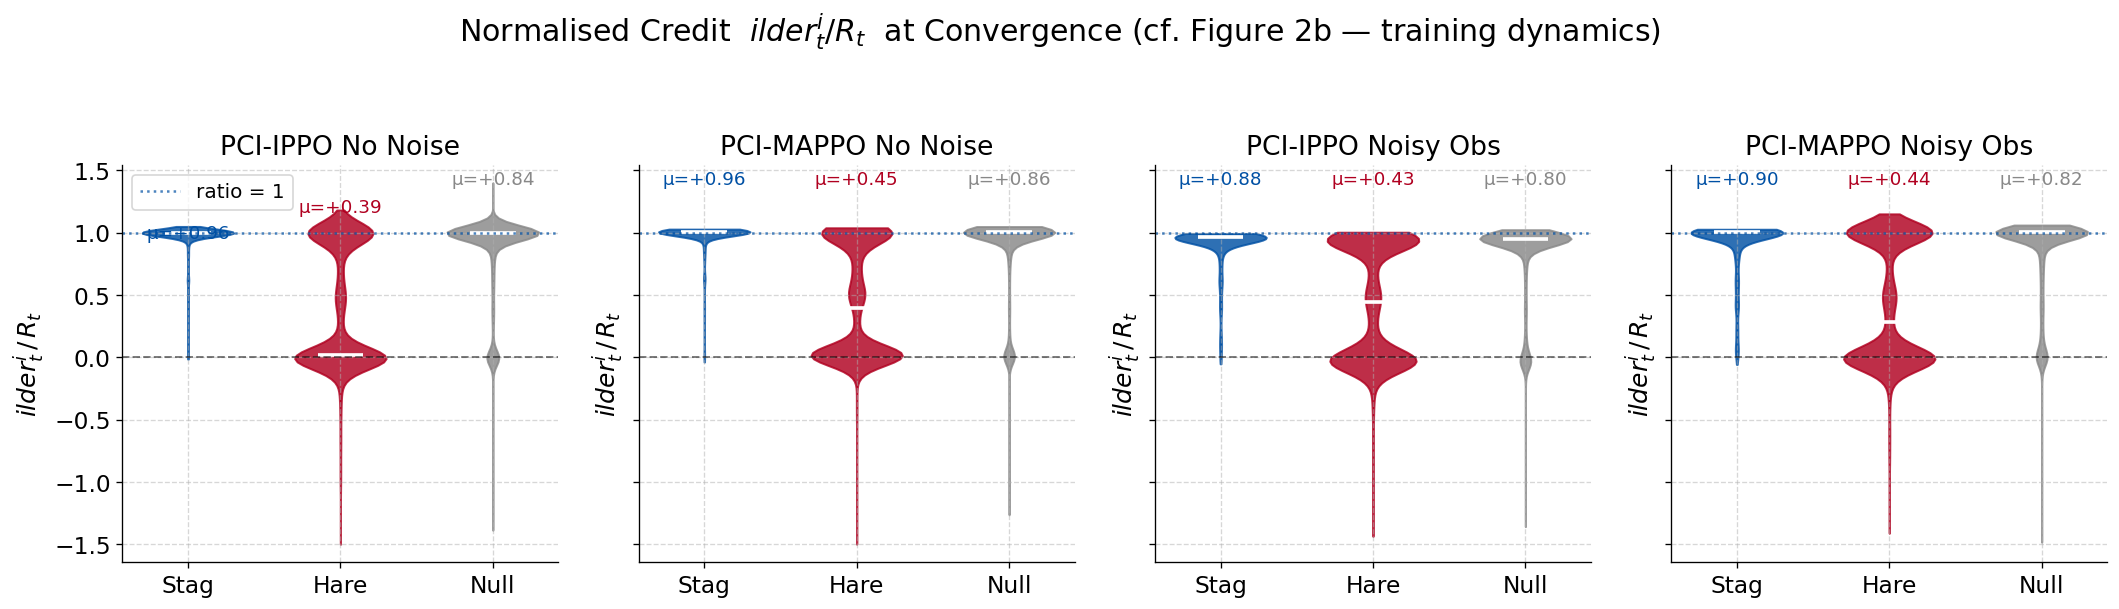

Saved: normalised_credit_at_convergence.pdf


In [18]:
# ── Figure 3: Normalised credit r̃/R at convergence ───────────────────────────
# Data flow:
#   credit_pol = R − baseline_pol   (policy-weighted, Eq.13)
#   ratio      = credit_pol / R     (only for timesteps where R > 0)
#   clip to [-1.5, 2.5] to suppress outliers from near-zero R values
# Static distribution at convergence — analogue of Figure 2b in the paper
# (paper shows this quantity over training steps; here we show it as a distribution
#  from the final checkpoint).
# Expected: Stag ≈ 1.0,  Hare ≈ 0.3–0.6,  Null ≈ 0

fig, axes = plt.subplots(1, 4, figsize=(20, 6), sharey=True)

for ax, key in zip(axes, list(all_variant_data.keys())):
    vd     = all_variant_data[key]
    q      = variant_q[key]
    color  = MODEL_COLORS[vd["model_type"]]
    scens  = q["scenario"]
    R      = q["reward"]
    credit = q["credit_pol"]

    pos    = np.array([0.0, 1.8, 3.6])
    _annot = []

    for idx, sc in enumerate(SCENARIO_ORDER):
        mask    = scens == sc
        nonzero = mask & (np.abs(R) > 1e-4)
        n       = nonzero.sum()
        if n == 0:
            continue
        ratio = np.clip(credit[nonzero] / R[nonzero], -1.5, 2.5)

        vp = ax.violinplot([ratio], positions=[pos[idx]], widths=1.0,
                            showmedians=True, showextrema=False)
        for body in vp["bodies"]:
            body.set_facecolor(SCENARIO_COLORS[sc]); body.set_alpha(0.82)
            body.set_edgecolor(SCENARIO_COLORS[sc]); body.set_linewidth(1.8)
        vp["cmedians"].set_color("white"); vp["cmedians"].set_linewidth(2.8)
        _annot.append((pos[idx], ratio.mean(), n, SCENARIO_COLORS[sc]))

    ax.axhline(1.0, color="#0050a4", lw=2.0, ls=":", alpha=0.7, label=r"$\tilde{r}/R = 1$")
    ax.axhline(0.0, color="black",   lw=1.5, ls="--", alpha=0.5)
    ax.set_xticks(pos)
    ax.set_xticklabels(SCENARIO_ORDER, fontsize=FS - 2)
    ax.set_ylabel(r"$\tilde{r}^i_t \,/\, R_t$", fontsize=FS - 1)
    ax.set_title(vd["display"].replace("\n", " "), fontsize=FS)
    ax.legend(fontsize=FS - 3, loc="upper right")

    y_top = ax.get_ylim()[1]
    for xp, mu, n, c in _annot:
        ax.text(xp, y_top * 0.96, f"μ={mu:+.2f}\nN={n}",
                ha="center", va="top", fontsize=FS - 5, color=c, fontweight="bold")

fig.suptitle(
    r"Normalised Credit  $\tilde{r}^i_t / R_t$  at Convergence"
    " (cf. Figure 2b — training dynamics)",
    fontsize=FS + 1, y=1.03,
)
plt.tight_layout()
plt.savefig(SAVE_DIR / "normalised_credit_at_convergence.pdf", dpi=200, bbox_inches="tight")
plt.show()
print("Saved: normalised_credit_at_convergence.pdf")

## Summary Statistics Table

In [19]:
# ── Latex-ready summary table ─────────────────────────────────────────────────
header = (
    f"{'Variant':<28}  {'Scenario':>8}  {'N':>6}  "
    f"{'h_fact':>8}  {'b_pol':>7}  {'credit':>8}  "
    f"{'R':>6}  {'credit/R':>9}  {'res_μ':>7}  {'res_σ':>7}"
)
print(header)
print("-" * len(header))

for key, q in variant_q.items():
    for sc in SCENARIO_ORDER:
        mask = q["scenario"] == sc
        n    = mask.sum()
        if n == 0:
            continue
        hf  = q["h_fact"][mask].mean()
        bp  = q["baseline_pol"][mask].mean()
        cr  = q["credit_pol"][mask].mean()
        r   = q["reward"][mask].mean()
        ratio = cr / r if abs(r) > 1e-5 else float("nan")
        mu_res = q["res_trained"][mask].mean()
        sd_res = q["res_trained"][mask].std()
        print(
            f"  {key:<26}  {sc:>8}  {n:>6}  "
            f"{hf:>+8.3f}  {bp:>+7.3f}  {cr:>+8.3f}  "
            f"{r:>+6.3f}  {ratio:>+9.3f}  {mu_res:>+7.4f}  {sd_res:>7.4f}"
        )
    print()

Variant                       Scenario       N    h_fact    b_pol    credit       R   credit/R    res_μ    res_σ
----------------------------------------------------------------------------------------------------------------
  PCI-IPPO No Noise               Stag    2690    +0.711   +0.069    +1.620  +1.689     +0.959  +0.9775   0.7943
  PCI-IPPO No Noise               Hare    5713    +0.745   +0.663    +0.458  +1.121     +0.409  +0.3759   0.5426
  PCI-IPPO No Noise               Null   95163    +0.072   +0.032    +0.088  +0.120     +0.734  +0.0480   0.3370

  PCI-MAPPO No Noise              Stag    2760    +0.753   +0.065    +1.625  +1.690     +0.961  +0.9373   0.8299
  PCI-MAPPO No Noise              Hare    5707    +0.665   +0.597    +0.531  +1.128     +0.471  +0.4629   0.5145
  PCI-MAPPO No Noise              Null   91571    +0.063   +0.018    +0.110  +0.128     +0.863  +0.0641   0.3479

  PCI-IPPO Noisy Obs              Stag    1950    +0.813   +0.202    +1.489  +1.691     +0.881